# Local Lipschitz ratio from the autoencoder-sampled sweep

Same analysis as `lipschitz_ratio_perturbed_sweep.ipynb`, but on `scripts.autoencoder.run_sampled_sweep`'s output instead of the vocab-perturbation sweep: for one sublayer `src -> dst`, each row is one independently-sampled ambient point `src_vec` (drawn from `src`'s trained autoencoder) and the real sublayer output `dst_vec` for that point (spliced into real context activations -- see `scripts/autoencoder/run_sampled_sweep.py`'s docstring).

Unlike the vocab sweep, samples are independent per **position** (the autoencoder is trained per `(sublayer, position)` pair), so positions are kept **separate** here rather than pooled: one ratio distribution and plot per `(sublayer, position)`.

```
g(x, y) = ||f(x) - f(y)|| / ||x - y||
```
computed via `pdist` over the `n` sampled points at each position (same recipe as the perturbed-sweep notebook -- `src_vec`/`dst_vec` share row ordering, so the ratio is elementwise, no re-indexing needed).

In [3]:
import os

import h5py
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.spatial.distance import pdist

from scripts.python.estimate_colipschitz_gpd import fit_gpd_tail

## Config

In [4]:
# Output dir from scripts.autoencoder.run_sampled_sweep, e.g.
# /local/scratch/$USER/new_jac/ae_sampled_sweep_test3 (local scratch --
# see CLAUDE.md's "local scratch, not NFS" convention; run this notebook
# via srun on mauao where scratch is mounted, or point SWEEP_DIR at wherever
# you pulled the shard(s) locally).
#
# simple_stories's last sublayer (add_34 -> add_36, per configs/simple_stories.toml)
# -- shards aren't checked into NFS (only the manifest/progress json are), so pull
# them first via execute.sharded_writer.load_shard_rows / ensure_local on a mauao
# node, or point SWEEP_DIR at wherever you pulled shard_*.h5 locally.
SWEEP_DIR = "/nfs-share/pa511/code_bases/new_jac/onnx_models/simple_stories/ae_sampled_sweep/"
SRC_LAYER = "add_34"
DST_LAYER = "add_36"
VARIANT = "alpha0.3"  # must match one of the {src}.{dst}.<variant>.sample{idx} dirs the sweep wrote, e.g. "alpha0.3" or "noise0.5"
SAMPLE_IDX = 0  # must match the --sample-idx used to generate this sweep
N_PAIRS_MAX = 20000  # subsample before pdist if a position has more than this many rows

## Load one sublayer's shard(s)

Small helper mirroring `execute.sharded_writer.load_shard_rows`, but reading directly off local scratch (no manifest/remote resolution needed for a notebook working against a single local run's output).

In [5]:
def load_sublayer_rows(sweep_dir: str, src: str, dst: str, variant: str, sample_idx: int) -> dict[str, np.ndarray]:
    layer_dir = os.path.join(sweep_dir, f"{src}.{dst}.{variant}.sample{sample_idx}")
    shard_paths = sorted(
        os.path.join(layer_dir, f)
        for f in os.listdir(layer_dir)
        if f.startswith("shard_") and f.endswith(".h5")
    )
    out: dict[str, list[np.ndarray]] = {"src_vec": [], "dst_vec": [], "pos": []}
    attrs = {}
    for p in shard_paths:
        with h5py.File(p, "r") as f:
            for k in out:
                out[k].append(f[k][:])
            attrs = dict(f.attrs)
    return {k: np.concatenate(v, axis=0) for k, v in out.items()}, attrs


rows, attrs = load_sublayer_rows(SWEEP_DIR, SRC_LAYER, DST_LAYER, VARIANT, SAMPLE_IDX)
print("attrs:", attrs)
print("total rows:", rows["src_vec"].shape[0])
seq = int(attrs["seq"])

attrs: {'alpha': np.float64(0.3), 'd_model': np.int64(384), 'n_samples': np.int64(1000), 'radius': 'global', 'row_end': np.int64(8000), 'row_start': np.int64(0), 'sample_idx': np.int64(0), 'seq': np.int64(8)}
total rows: 8000


## Per-position Lipschitz ratio

In [6]:
def ratio_for_position(rows: dict[str, np.ndarray], pos: int, n_pairs_max: int, seed: int = 0):
    mask = rows["pos"] == pos
    src = rows["src_vec"][mask]
    dst = rows["dst_vec"][mask]
    n = src.shape[0]
    if n > n_pairs_max:
        idx = np.random.default_rng(seed).choice(n, n_pairs_max, replace=False)
        src, dst = src[idx], dst[idx]
    input_dist = pdist(src)
    output_dist = pdist(dst)
    # batched_sample resamples candidates WITH replacement (torch.multinomial),
    # so exact-duplicate points across rows are expected (more likely at low
    # ESS) -- pairs with input_dist == 0 make the ratio 0/0 = nan, so drop
    # them rather than letting them poison min/median/max and the GPD fit.
    nonzero = input_dist > 0
    n_dropped = (~nonzero).sum()
    if n_dropped:
        print(f"  pos={pos}: dropping {n_dropped} zero-input-distance pair(s) (duplicate sampled points)")
    return input_dist[nonzero], output_dist[nonzero]


per_pos_results = {}
for pos in range(seq):
    input_dist, output_dist = ratio_for_position(rows, pos, N_PAIRS_MAX)
    g = output_dist / input_dist
    result = fit_gpd_tail(g, threshold=None, threshold_quantile=None, n_tail_min=200)
    per_pos_results[pos] = dict(input_dist=input_dist, output_dist=output_dist, g=g, result=result)
    print(f"pos={pos}: N={g.size} pairs, g min/median/max = {g.min():.4g}/{np.median(g):.4g}/{g.max():.4g}, "
          f"c_hat={result['c_hat']}")

  pos=0: dropping 102 zero-input-distance pair(s) (duplicate sampled points)
pos=0: N=499398 pairs, g min/median/max = 0.8887/1.295/2.08, c_hat=0.8303265954131508
  pos=1: dropping 94 zero-input-distance pair(s) (duplicate sampled points)
pos=1: N=499406 pairs, g min/median/max = 1.029/1.358/2.191, c_hat=0.8431993244060192
  pos=2: dropping 141 zero-input-distance pair(s) (duplicate sampled points)
pos=2: N=499359 pairs, g min/median/max = 0.9455/1.379/2.142, c_hat=0.8083279273916344
  pos=3: dropping 98 zero-input-distance pair(s) (duplicate sampled points)
pos=3: N=499402 pairs, g min/median/max = 1.05/1.453/2.356, c_hat=0.6018067036816868
  pos=4: dropping 77 zero-input-distance pair(s) (duplicate sampled points)
pos=4: N=499423 pairs, g min/median/max = 1.104/1.468/2.525, c_hat=0.9417908295990509
  pos=5: dropping 105 zero-input-distance pair(s) (duplicate sampled points)
pos=5: N=499395 pairs, g min/median/max = 1.051/1.471/2.373, c_hat=None
  pos=6: dropping 118 zero-input-distan

## Plots: output vs input distance, per position

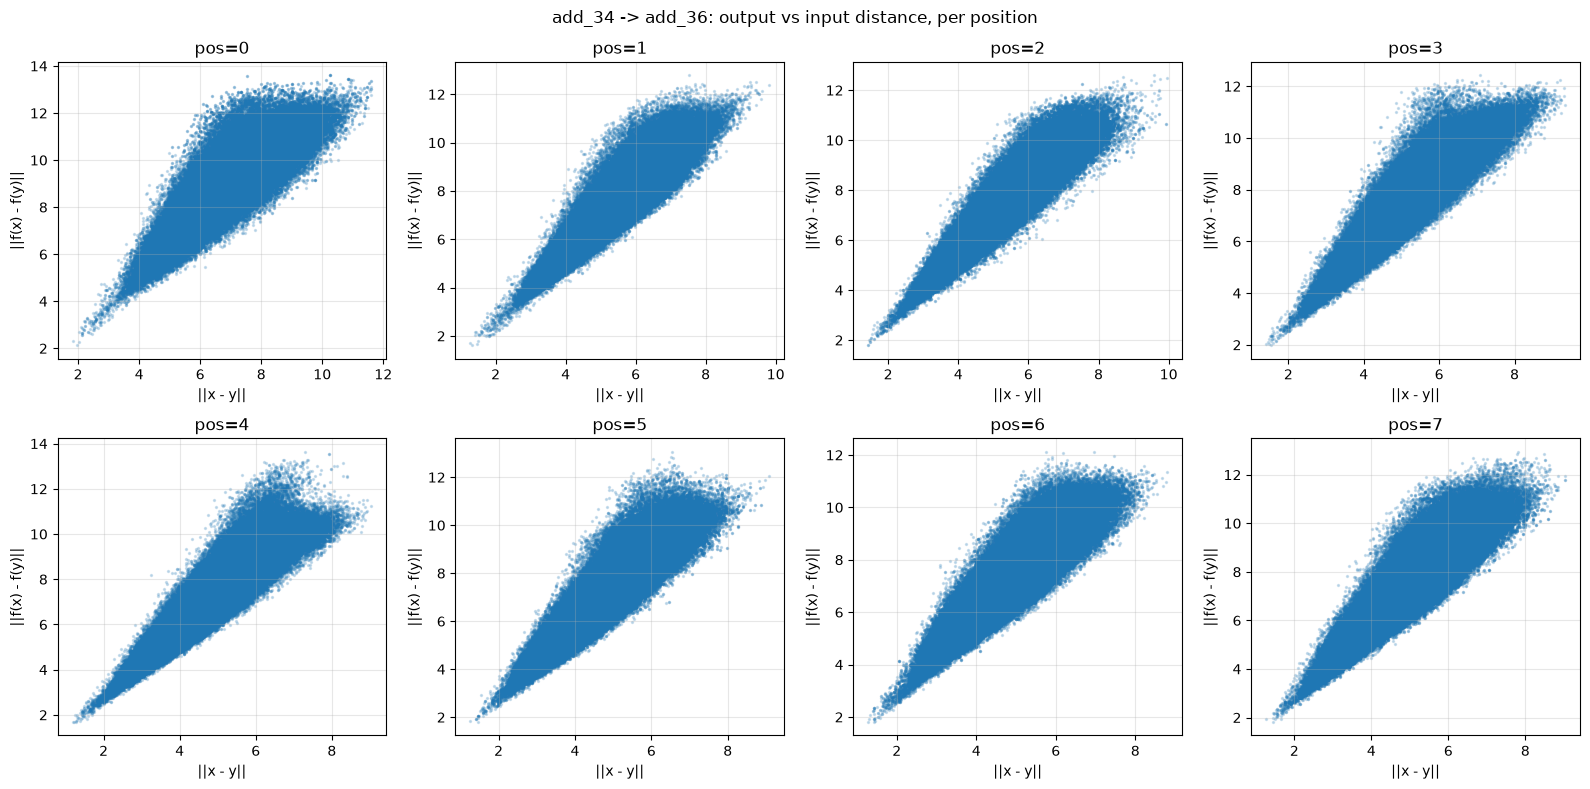

In [7]:
fig, axes = plt.subplots(2, (seq + 1) // 2, figsize=(4 * ((seq + 1) // 2), 8), squeeze=False)
axes = axes.flatten()
for pos in range(seq):
    r = per_pos_results[pos]
    ax = axes[pos]
    ax.scatter(r["input_dist"], r["output_dist"], s=2, alpha=0.2)
    ax.set_xlabel("||x - y||")
    ax.set_ylabel("||f(x) - f(y)||")
    ax.set_title(f"pos={pos}")
    ax.grid(True, alpha=0.3)
for ax in axes[seq:]:
    ax.axis("off")
fig.suptitle(f"{SRC_LAYER} -> {DST_LAYER}: output vs input distance, per position")
fig.tight_layout()
plt.show()

## Plots: Lipschitz ratio distribution + GPD tail, per position

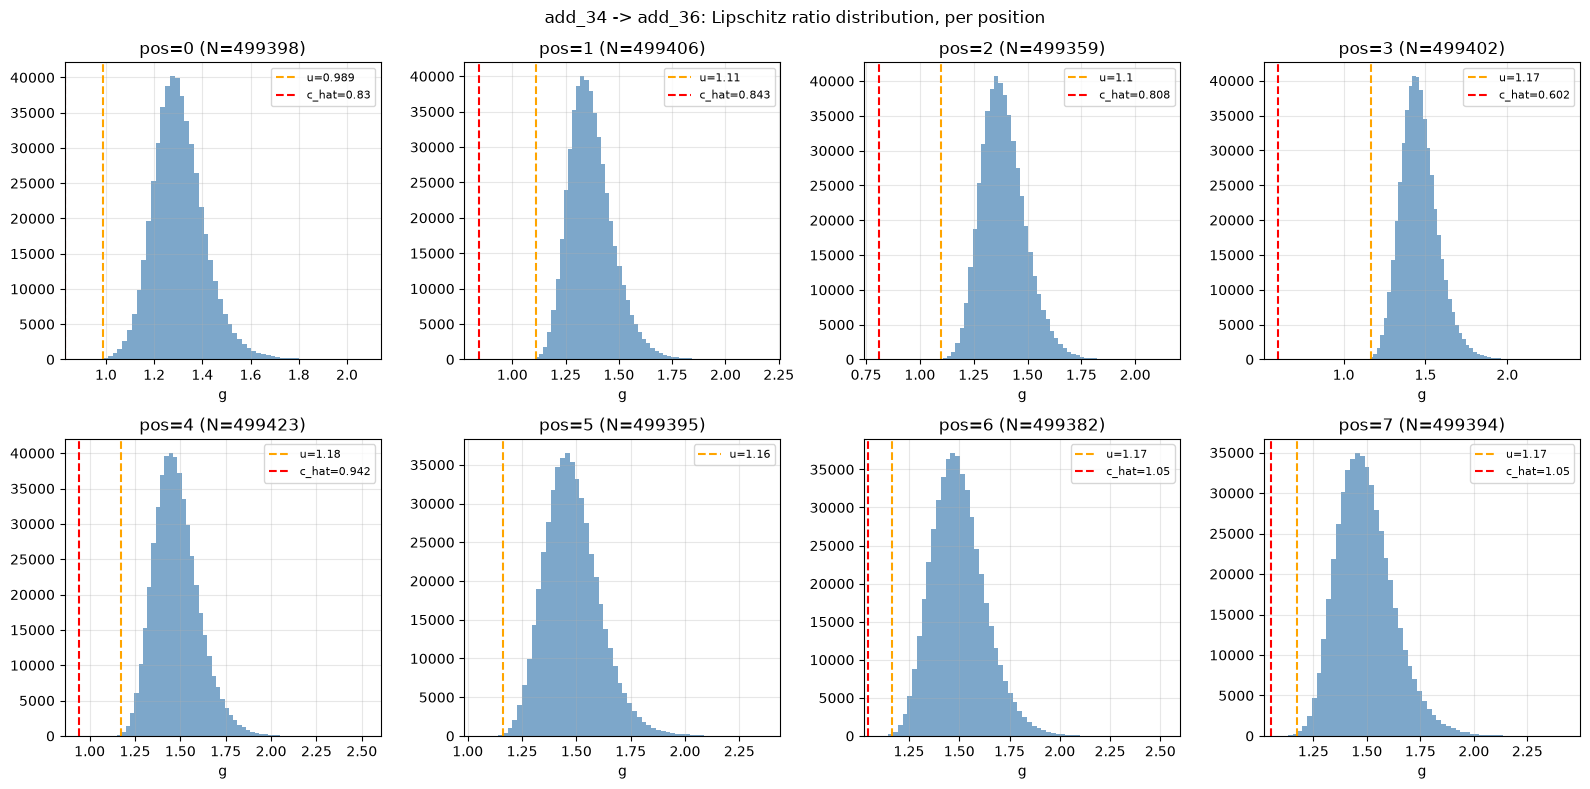

In [8]:
from scipy.stats import genpareto

fig, axes = plt.subplots(2, (seq + 1) // 2, figsize=(4 * ((seq + 1) // 2), 8), squeeze=False)
axes = axes.flatten()
for pos in range(seq):
    r = per_pos_results[pos]
    g, result = r["g"], r["result"]
    threshold = result["threshold"]
    ax = axes[pos]
    ax.hist(g, bins=60, color="steelblue", alpha=0.7)
    ax.axvline(threshold, color="orange", linestyle="--", label=f"u={threshold:.3g}")
    if result["c_hat"] is not None:
        ax.axvline(result["c_hat"], color="red", linestyle="--", label=f"c_hat={result['c_hat']:.3g}")
    ax.set_xlabel("g")
    ax.set_title(f"pos={pos} (N={g.size})")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
for ax in axes[seq:]:
    ax.axis("off")
fig.suptitle(f"{SRC_LAYER} -> {DST_LAYER}: Lipschitz ratio distribution, per position")
fig.tight_layout()
plt.show()

## Summary table: c_hat per position

In [9]:
print(f"{'pos':>4}  {'N':>8}  {'g_min':>10}  {'threshold':>10}  {'c_hat':>10}  {'se_c_hat':>10}")
for pos in range(seq):
    result = per_pos_results[pos]["result"]
    c_hat = result["c_hat"]
    se = result.get("se_c_hat")
    print(
        f"{pos:>4}  {result['n_samples']:>8}  {result['g_min_observed']:>10.4g}  "
        f"{result['threshold']:>10.4g}  {c_hat if c_hat is not None else float('nan'):>10.4g}  "
        f"{se if se is not None else float('nan'):>10.4g}"
    )

 pos         N       g_min   threshold       c_hat    se_c_hat
   0    499398      0.8887      0.9894      0.8303     0.05575
   1    499406       1.029       1.109      0.8432      0.2472
   2    499359      0.9455       1.099      0.8083      0.1512
   3    499402        1.05       1.165      0.6018       1.102
   4    499423       1.104       1.175      0.9418      0.2506
   5    499395       1.051        1.16         nan         nan
   6    499382       1.099       1.165       1.048     0.04366
   7    499394       1.087       1.171       1.051     0.03083
